In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [3]:
url = "https://raw.githubusercontent.com/madmashup/targeted-marketing-predictive-engine/master/banking.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Column Values:")
print(df['y'].value_counts(dropna=False))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_

In [ ]:
df = df.dropna(subset=['y']).copy()

X = df.drop(columns=['y'])
y = df['y'].astype(str).str.strip().str.lower()

X = pd.get_dummies(X, drop_first=True)

valid = y.isin(['yes', 'no'])

X = X.loc[valid]
y = y.loc[valid].map({'no': 0, 'yes': 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (0, 53)
Target shape: (0,)

Target distribution:
Series([], Name: count, dtype: int64)


In [ ]:
X = df.drop(columns=['y'])
X = pd.get_dummies(X, drop_first=True)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (32950, 53)
Testing data: (8238, 53)


In [9]:
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [10]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Subscription', 'Subscription']
    )
)

Model Accuracy: 84.61 %

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.99      0.84      0.91      7310
   Subscription       0.42      0.91      0.57       928

       accuracy                           0.85      8238
      macro avg       0.70      0.87      0.74      8238
   weighted avg       0.92      0.85      0.87      8238



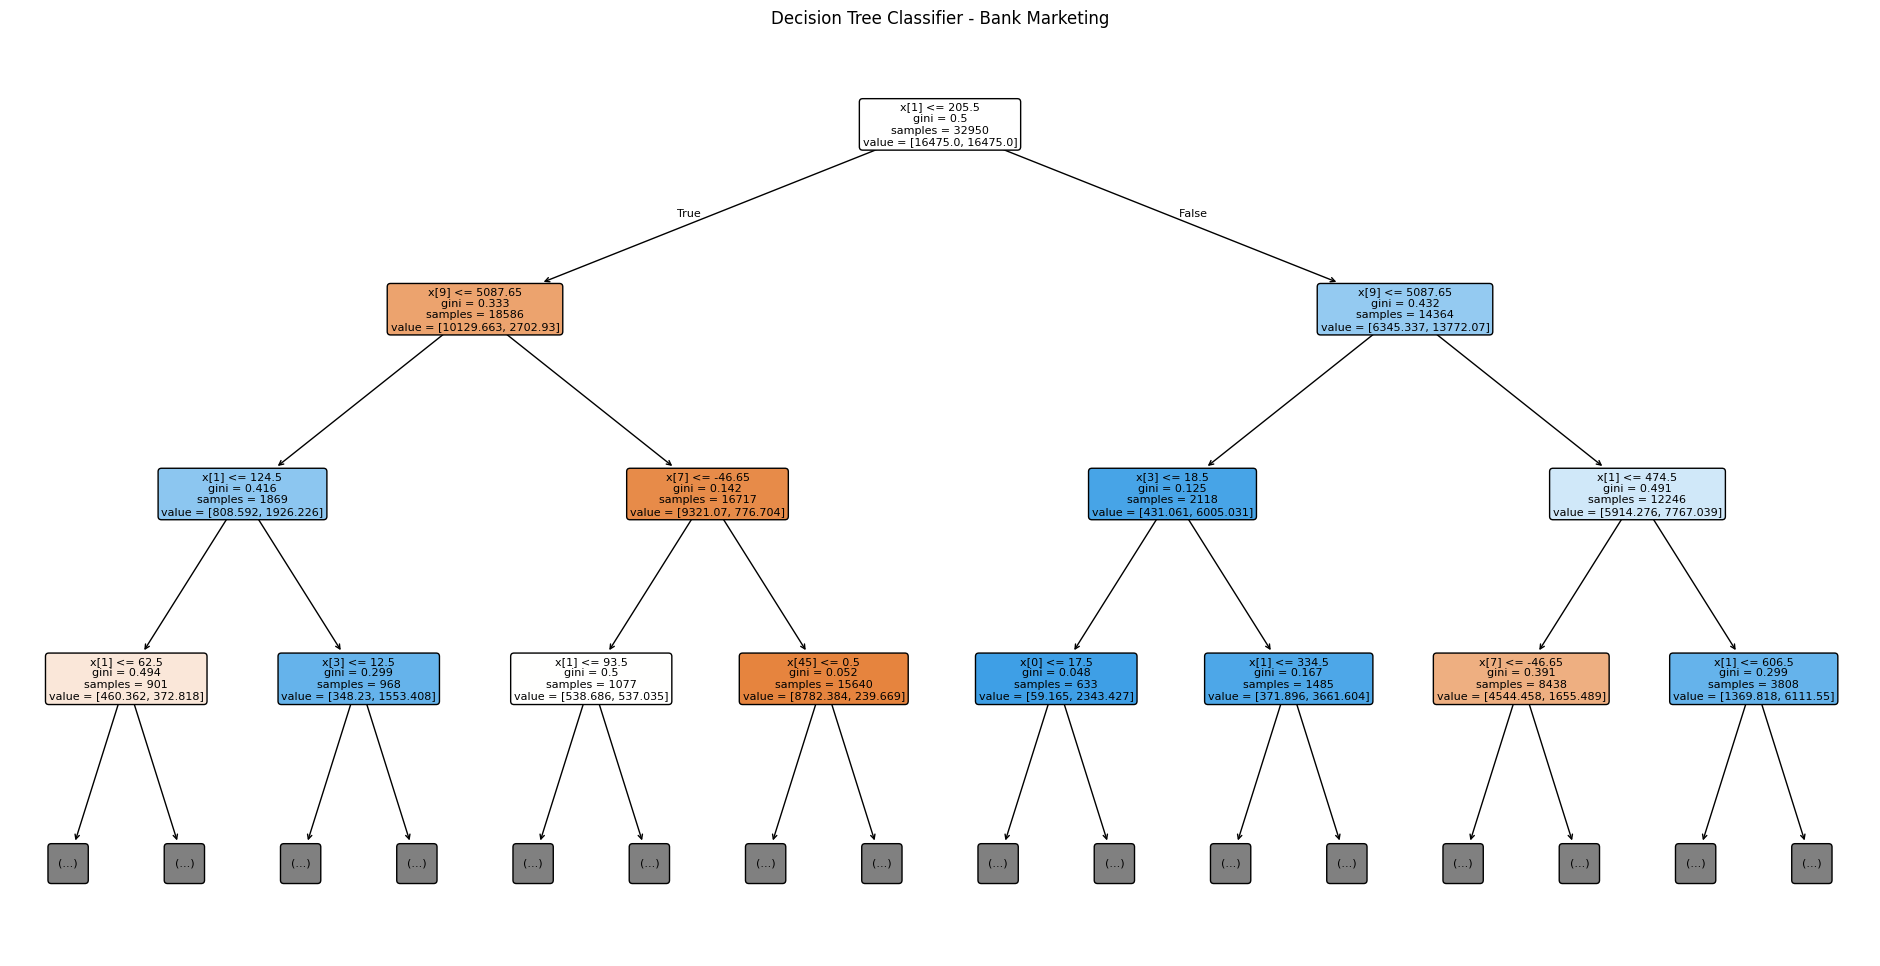

In [11]:
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier - Bank Marketing")
plt.show()

Conclusion

In this task, I built a Decision Tree Classifier using Python and Scikit-learn. I prepared the Bank Marketing dataset, trained the model, evaluated its performance, and visualized the decision tree. This project helped me understand the basics of machine learning classification.